In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from scipy.stats import norm, chi2

V0 = 1_000_000
alpha = 0.97
beta = 0.02
M = 125_000

np.random.seed(42)


In [2]:

# Download historical Apple prices
data = yf.download(
    "AAPL",
    start="2016-11-01",
    end="2018-11-01",
    auto_adjust=True,
    progress=False
)

# Handle possible MultiIndex columns
if isinstance(data.columns, pd.MultiIndex):
    prices = data["Close"]["AAPL"]
else:
    prices = data["Close"]

prices = prices.dropna()

# Daily log returns
log_returns = np.log(prices / prices.shift(1)).dropna()

n = len(log_returns)
mu_hat = log_returns.mean()
sigma_hat = log_returns.std(ddof=1)
variance_hat = sigma_hat ** 2

print(f"Number of returns: {n}")
print(f"Sample mean:       {mu_hat:.8f}")
print(f"Sample volatility: {sigma_hat:.8f}")
print(f"Sample variance:   {variance_hat:.10f}")
print(f"First price date:  {prices.index.min().date()}")
print(f"Last price date:   {prices.index.max().date()}")


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()


Number of returns: 503
Sample mean:       0.00140555
Sample volatility: 0.01292845
Sample variance:   0.0001671448
First price date:  2016-11-01
Last price date:   2018-10-31


In [3]:
# Part (a): VaR estimates

# 1. Historical VaR using empirical loss distribution
historical_losses = V0 * (1 - np.exp(log_returns))
var_historical = np.quantile(historical_losses, alpha)

# 2. Theoretical Normal VaR
z = norm.ppf(1 - alpha)

var_theoretical = V0 * (
    1 - np.exp(mu_hat + sigma_hat * z)
)

print("PART (a): VaR ESTIMATES")
print("-" * 45)
print(f"Historical VaR (97%): ${var_historical:,.2f}")
print(f"Theoretical VaR (97%): ${var_theoretical:,.2f}")
print(f"Difference: ${var_theoretical - var_historical:,.2f}")


PART (a): VaR ESTIMATES
---------------------------------------------
Historical VaR (97%): $24,918.92
Theoretical VaR (97%): $22,649.75
Difference: $-2,269.17


In [4]:
# Part (a): 98% CI for theoretical VaR
df = n - 1

q_low = chi2.ppf(beta / 2, df)
q_high = chi2.ppf(1 - beta / 2, df)

# Confidence interval for volatility
sigma_lower = np.sqrt(df * variance_hat / q_high)
sigma_upper = np.sqrt(df * variance_hat / q_low)

# Transform volatility CI to VaR CI
var_lower_a = V0 * (
    1 - np.exp(mu_hat + sigma_lower * z)
)

var_upper_a = V0 * (
    1 - np.exp(mu_hat + sigma_upper * z)
)

print("PART (a): 98% CONFIDENCE INTERVAL")
print("-" * 45)
print(f"Volatility lower bound: {sigma_lower:.6f}")
print(f"Volatility upper bound: {sigma_upper:.6f}")
print(f"VaR lower bound: ${var_lower_a:,.2f}")
print(f"VaR upper bound: ${var_upper_a:,.2f}")


PART (a): 98% CONFIDENCE INTERVAL
---------------------------------------------
Volatility lower bound: 0.012042
Volatility upper bound: 0.013949
VaR lower bound: $21,018.70
VaR upper bound: $24,523.65


In [5]:
# Part (b): Monte Carlo simulation
rng = np.random.default_rng(42)

# Step 1: Simulate volatility variance
chi_samples = rng.chisquare(df=n-1, size=M)

sigma2_samples = (
    (n - 1) * variance_hat / chi_samples
)
sigma_samples = np.sqrt(sigma2_samples)

# Step 2: Simulate the unknown mean
mu_samples = rng.normal(
    loc=mu_hat,
    scale=sigma_samples / np.sqrt(n),
    size=M
)

# Step 3: Calculate theoretical VaR for each trial
var_samples = V0 * (
    1 - np.exp(mu_samples + sigma_samples * z)
)

# Step 4: Average VaR and empirical CI
var_mean_b = np.mean(var_samples)

var_lower_b = np.quantile(var_samples, beta / 2)
var_upper_b = np.quantile(var_samples, 1 - beta / 2)

print("PART (b): MONTE CARLO RESULTS")
print("-" * 45)
print(f"Number of trials: {M:,}")
print(f"Average VaR: ${var_mean_b:,.2f}")
print(f"98% CI: (${var_lower_b:,.2f}, "
      f"${var_upper_b:,.2f})")


PART (b): MONTE CARLO RESULTS
---------------------------------------------
Number of trials: 125,000
Average VaR: $22,685.74
98% CI: ($20,583.57, $24,971.84)


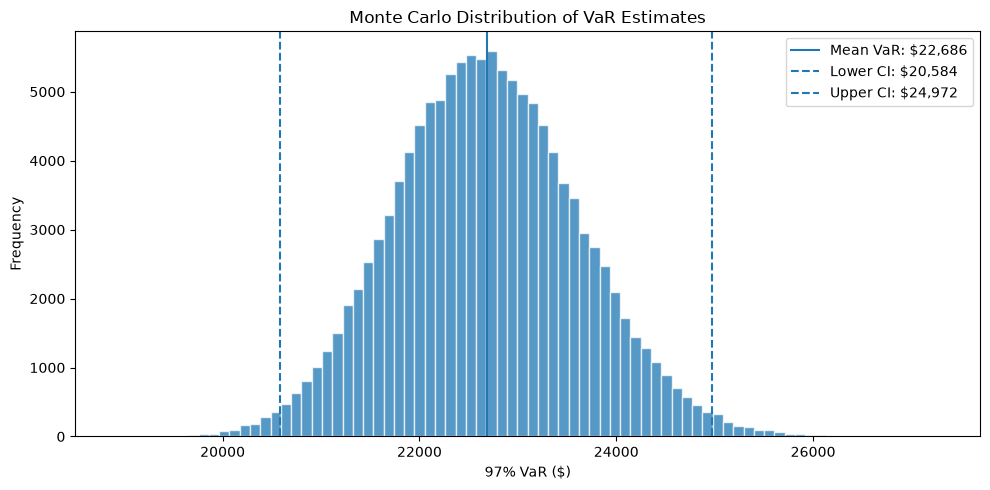

In [6]:
plt.figure(figsize=(10, 5))

plt.hist(
    var_samples,
    bins=80,
    alpha=0.75,
    edgecolor="white"
)

plt.axvline(
    var_mean_b, linestyle="-",
    label=f"Mean VaR: ${var_mean_b:,.0f}"
)
plt.axvline(
    var_lower_b, linestyle="--",
    label=f"Lower CI: ${var_lower_b:,.0f}"
)
plt.axvline(
    var_upper_b, linestyle="--",
    label=f"Upper CI: ${var_upper_b:,.0f}"
)

plt.xlabel("97% VaR ($)")
plt.ylabel("Frequency")
plt.title("Monte Carlo Distribution of VaR Estimates")
plt.legend()
plt.tight_layout()
plt.show()


In [7]:
results = pd.DataFrame({
    "Method": [
        "Historical VaR",
        "Normal Theoretical VaR",
        "Part (a): Known Mean",
        "Part (b): Unknown Mean and Volatility"
    ],
    "VaR Estimate ($)": [
        var_historical,
        var_theoretical,
        var_theoretical,
        var_mean_b
    ],
    "98% CI Lower ($)": [
        np.nan,
        np.nan,
        var_lower_a,
        var_lower_b
    ],
    "98% CI Upper ($)": [
        np.nan,
        np.nan,
        var_upper_a,
        var_upper_b
    ]
})

print(results.round(2).to_string(index=False))

print("\nComparison:")
print(f"Part (a) CI width: ${var_upper_a - var_lower_a:,.2f}")
print(f"Part (b) CI width: ${var_upper_b - var_lower_b:,.2f}")


                               Method  VaR Estimate ($)  98% CI Lower ($)  98% CI Upper ($)
                       Historical VaR          24918.92               NaN               NaN
               Normal Theoretical VaR          22649.75               NaN               NaN
                 Part (a): Known Mean          22649.75          21018.70          24523.65
Part (b): Unknown Mean and Volatility          22685.74          20583.57          24971.84

Comparison:
Part (a) CI width: $3,504.96
Part (b) CI width: $4,388.27


### Comparison of VaR Estimates and Confidence Intervals

Using Apple's daily log returns from November 2016 to October 2018, the historical 97% VaR is USD24,918.92, while the theoretical Normal VaR is USD22,649.75. The historical estimate is approximately 10.0% higher, suggesting that the Normal model may underestimate downside risk for this sample.

In Part (a), assuming the mean return is known, the 98% confidence interval for VaR is [USD21,018.70, USD24,523.65], with a width of USD3,504.96.

In Part (b), allowing both the mean and volatility to be uncertain and using 125,000 Monte Carlo simulations, the average VaR is USD22,685.74, with a 98% confidence interval of [USD20,583.57, USD24,971.84]. The interval width increases to USD4,388.27, approximately 25.2% wider than in Part (a).

The point estimates from Parts (a) and (b) are very similar, but the confidence interval in Part (b) is wider because it incorporates uncertainty in both parameters rather than volatility alone. This demonstrates that parameter estimation uncertainty can materially affect the reliability of VaR estimates, even when their point estimates remain nearly unchanged.

These confidence intervals quantify parameter uncertainty under the assumed Normal model and do not capture additional model risk arising from potential distributional misspecification.